<a href="https://colab.research.google.com/github/nurilhuda05/Pembelajaran_Mesin_2026/blob/main/TG11_244107020004_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

### **Langkah 1 - Import Library**

In [353]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

### **Langkah 2 - Membuat Data Dummy**

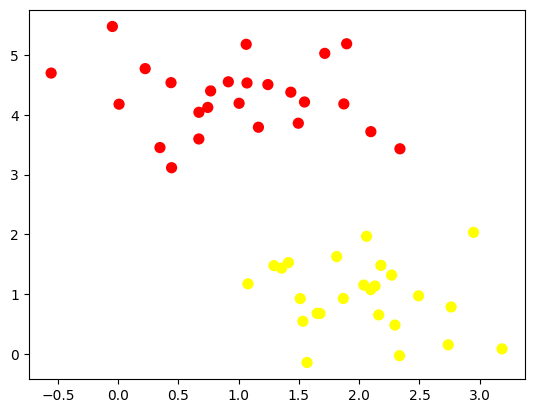

In [354]:
from sklearn.datasets import make_blobs

# Membuat data dengan dua kelas
X, y = make_blobs(
    n_samples=50,
    centers=2,
    random_state=0,
    cluster_std=0.60
)


plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

### **Langkah 3 - Membuat Ilustrasi Garis Pemisah**

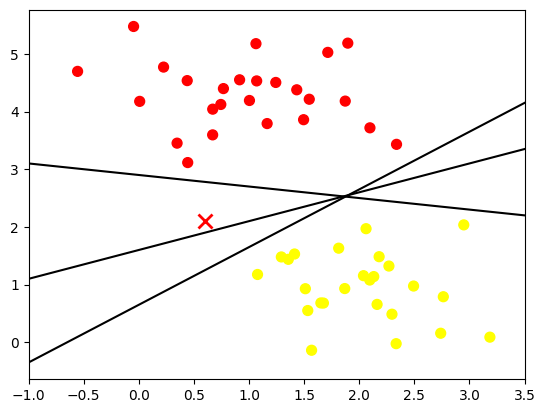

In [355]:
# Rentang sumbu x untuk menggambar garis
xfit = np.linspace(-1, 3.5)

# Plot data dari Langkah 2
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Titik data baru 'x'
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

# Tiga garis pemisah yang berbeda, dengan format (gradien m, intersep b)
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

# Batas sumbu x
plt.xlim(-1, 3.5)
plt.show()

### **Langkah 4 - Ilustrasi Margin**

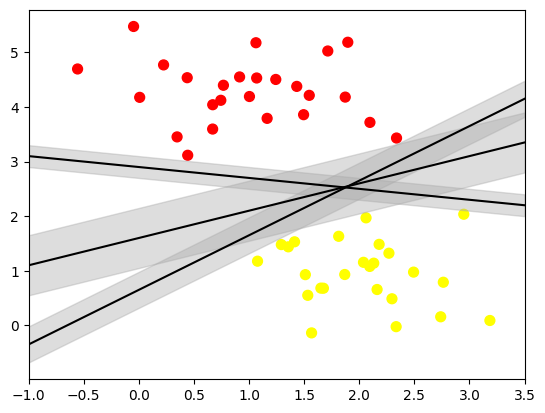

In [356]:
# Membuat rentang nilai untuk garis
xfit = np.linspace(-1, 3.5)

# Menampilkan data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Membuat beberapa garis pemisah dan margin
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(
        xfit,
        yfit - d,
        yfit + d,
        edgecolor='none',
        color='#AAAAAA',
        alpha=0.4
    )

# Mengatur batas sumbu X
plt.xlim(-1, 3.5)
plt.show()

### **Langkah 5 - Fitting Model**

#### **5A - Melatih Model SVM**

In [357]:
# Import algoritma SVM
from sklearn.svm import SVC

# Membuat model SVM dengan kernel linear
model = SVC(kernel='linear', C=1E10)

# Melatih model menggunakan data dummy
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

#### **5B - Membuat fungsi visualisasi garis pemisah**

In [358]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### **5C - Menampilkan hasil model SVM**

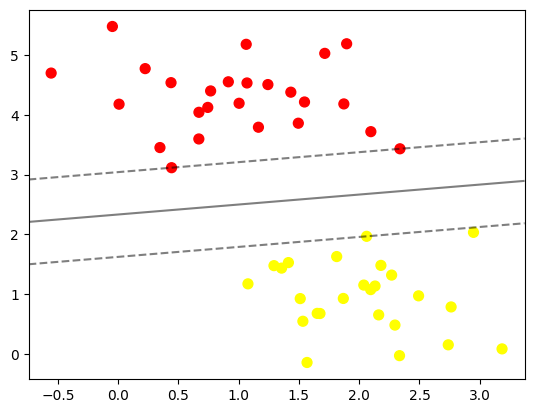

In [359]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

plot_svc_decision_function(model)

plt.show()

#### **5D - Melihat Support Vector**

In [360]:
# Menampilkan titik yang menjadi support vector
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

### **Langkah 6 - Membandingkan Model dengan Jumlah Data Berbeda**

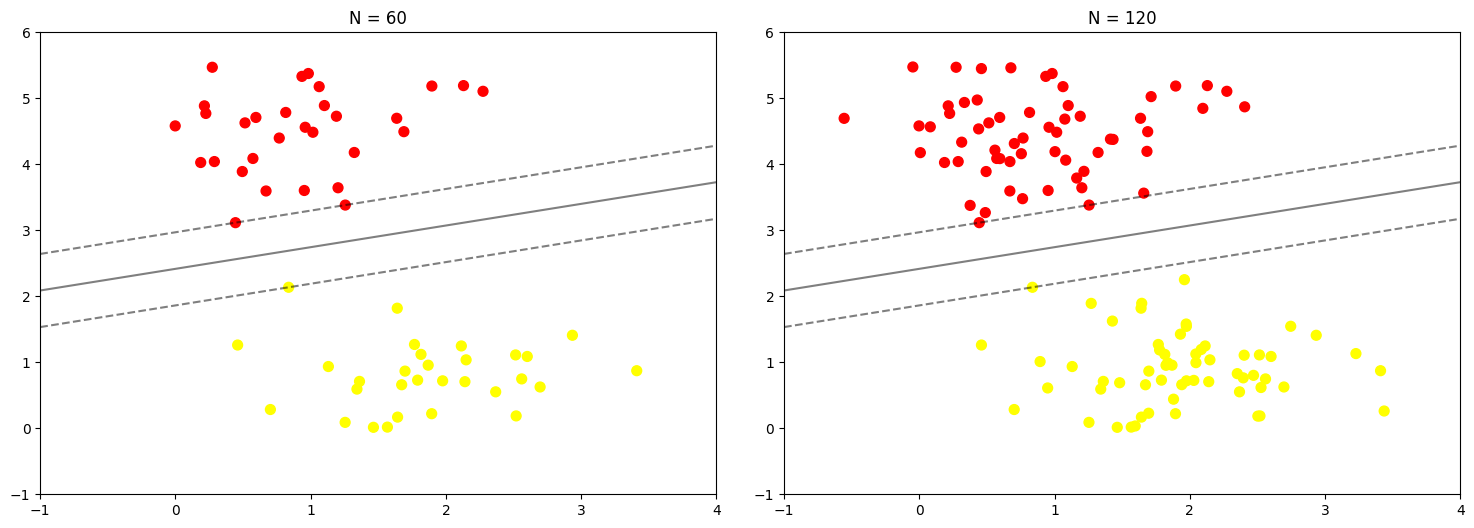

In [361]:
# Fungsi untuk membuat dan menampilkan model SVM
def plot_svm(N=10, ax=None):
    # Membuat 200 data dummy
    X, y = make_blobs(
        n_samples=200,
        centers=2,
        random_state=0,
        cluster_std=0.60
    )

    # Mengambil sejumlah data sesuai N
    X = X[:N]
    y = y[:N]

    # Membuat dan melatih model SVM
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    # Menampilkan data
    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

    # Mengatur batas grafik
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)

    # Menampilkan garis pemisah dan margin
    plot_svc_decision_function(model, ax)


# Membuat dua grafik perbandingan
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Menampilkan model dengan 60 dan 120 data
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {}'.format(N))

plt.show()

### **Langkah 7 - Interaksi Jumlah Data Menggunakan ipywidgets**

#### **7A - Instalasi library**

In [362]:
!pip install ipywidgets

#### **7B - Membuat tampilan interaktif**

In [363]:
# Import library untuk interaksi
from ipywidgets import interact, fixed

# Menampilkan model dengan pilihan jumlah data
interact(plot_svm, N=[10,50,100,150,200], ax=fixed(None))

plt.show()

interactive(children=(Dropdown(description='N', options=(10, 50, 100, 150, 200), value=10), Output()), _dom_cl…

# **PRAKTIKUM 2**

### **Langkah 1 - Ilustrasi Data Non-Linier**

#### **1A - Import Library**

In [364]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

#### **1B - Membuat Kembali Fungsi Plotting**

In [365]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### **1C - Membuat Data Dummy Non-Linier**

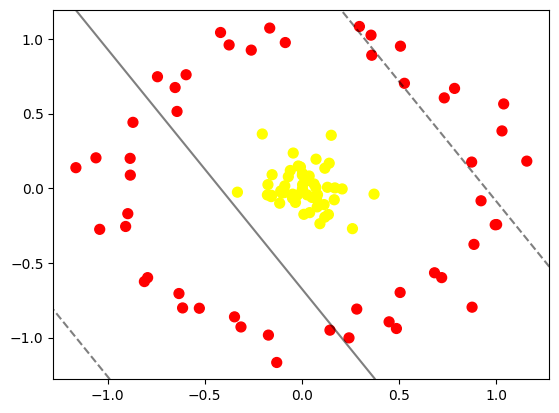

In [366]:
# Import library untuk membuat data lingkaran
from sklearn.datasets import make_circles

# Membuat data dummy non-linier
X, y = make_circles(
    n_samples=100,
    factor=0.1,
    noise=0.1,
    random_state=42
)

# Melatih SVM dengan kernel linear
clf = SVC(kernel='linear')
clf.fit(X, y)

# Menampilkan visualisasi data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menampilkan garis pemisah
plot_svc_decision_function(clf, plot_support=False)

plt.show()

Hasil grafik yang diperoleh berbeda dengan modul karena pada kode ini ditambahkan parameter random_state=42, sedangkan modul tidak menggunakannya. Parameter tersebut membuat data yang dihasilkan tetap sama setiap kali kode dijalankan. Tanpa random_state, data dapat berubah setiap kali dijalankan.

#### **1D - Visualisasi Data dalam Bentuk 3D**

In [367]:
# Import library untuk visualisasi 3D dan interaksi
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# Menghitung proyeksi radial
r = np.exp(-(X**2).sum(1))

# Membuat fungsi visualisasi 3D
def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')

    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')

    ax.view_init(elev=elev, azim=azim)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')


# Menampilkan grafik interaktif
interact(
    plot_3D,
    elev=[-90, 45, 30, 20, 10],
    azim=(-180, 180),
    X=fixed(X),
    y=fixed(y)
)

plt.show()

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

### **Langkah 2 - Fitting Model dengan Kernel RBF**

#### **2A - Melatih model SVM**

In [368]:
# Membuat model SVM dengan kernel RBF
clf = SVC(kernel='rbf', C=1E6)

# Melatih model menggunakan data dummy
clf.fit(X, y)

SVC(C=1000000.0)

#### **2B - Menampilkan hasil klasifikasi**

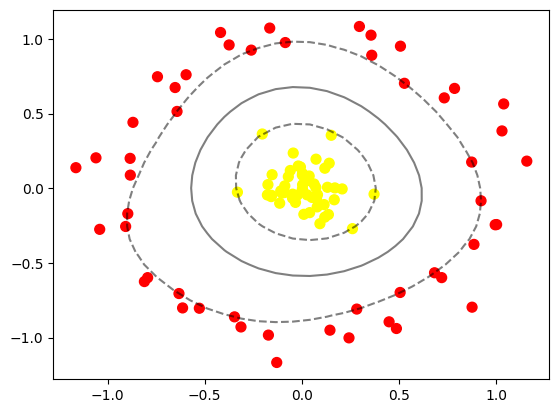

In [369]:
# Menampilkan data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menampilkan garis pemisah dan margin
plot_svc_decision_function(clf)

# Menampilkan support vector
plt.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=300,
    linewidth=1,
    facecolors='none'
)

plt.show()

# **PRAKTIKUM 3**

### **Langkah 1 - Import Library dan Buat Fungsi Plotting**

#### **1A - Import library**

In [370]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

#### **1B - Membuat fungsi plotting**

In [371]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### **Langkah 2 - Buat Data Dummy**

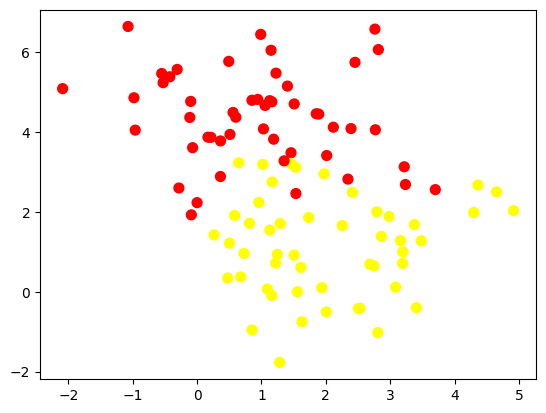

In [372]:
X, y = make_blobs(
    n_samples=100,
    centers=2,
    random_state=0,
    cluster_std=1.2
)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

### **Langkah 3 - Analisis Dampak Tunning**

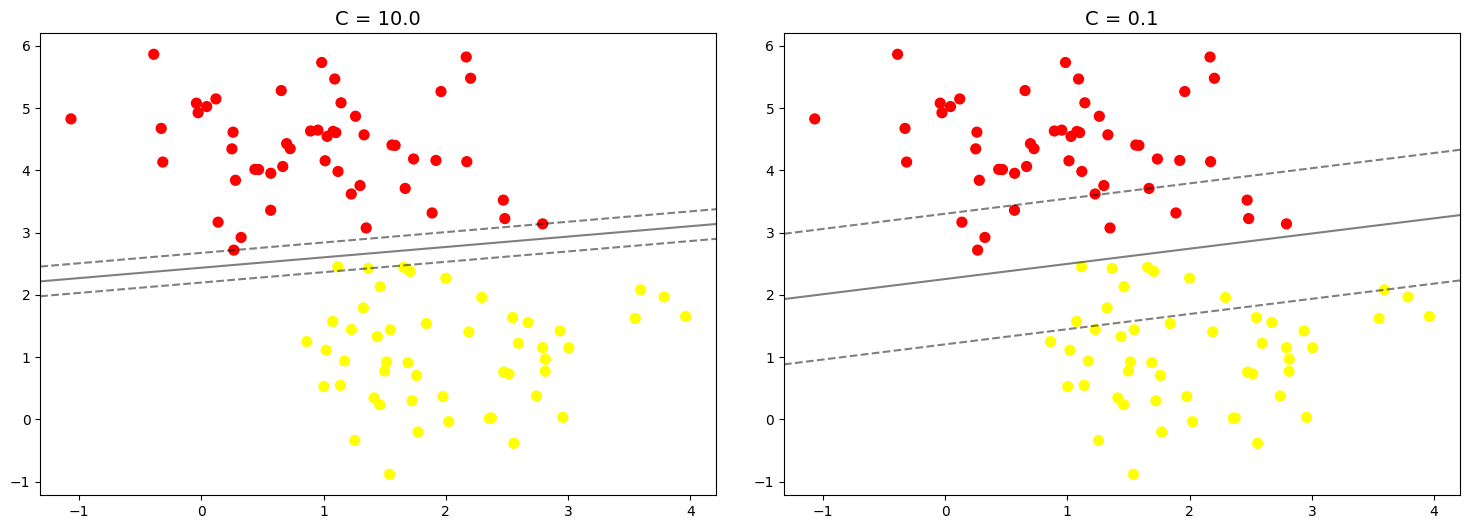

In [373]:
# Membuat dataset dengan 100 data dan 2 kelompok
X, y = make_blobs(
    n_samples=100,
    centers=2,
    random_state=0,
    cluster_std=0.8
)

# Membuat tempat untuk menampilkan 2 grafik
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Membandingkan nilai C = 10.0 dan C = 0.1
for axi, C in zip(ax, [10.0, 0.1]):

    # Membuat dan melatih model SVM dengan kernel linear
    model = SVC(kernel='linear', C=C).fit(X, y)

    # Menampilkan titik data berdasarkan kelompoknya
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

    # Menampilkan batas pemisah dan margin SVM
    plot_svc_decision_function(model, axi)

    # Menandai support vectors dengan lingkaran kosong
    axi.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=300,
        lw=1,
        facecolors='none'
    )

    # Memberikan judul sesuai nilai C
    axi.set_title('C = {0:.1f}'.format(C), size=14)

# Menampilkan kedua grafik
plt.show()

# **PRAKTIKUM 4**

### **Langkah 0 - Unduh Dataset**

In [374]:
from sklearn.datasets import fetch_lfw_people

# Mengunduh dataset dengan minimal 60 foto untuk setiap tokoh
faces = fetch_lfw_people(min_faces_per_person=60)

# Menampilkan nama tokoh yang terdapat dalam dataset
print(faces.target_names)

# Menampilkan jumlah tokoh
print(len(faces.target_names))

# Menampilkan ukuran data citra wajah
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


### **Langkah 1 - Inspeksi Citra Wajah**

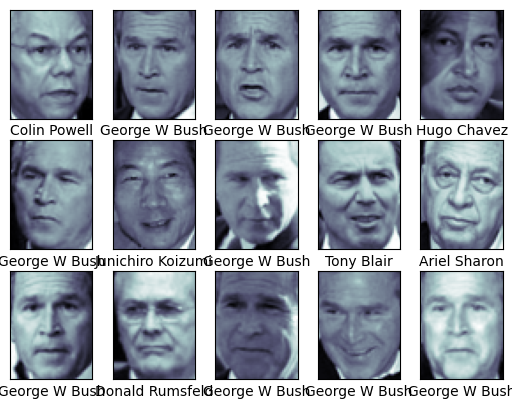

In [375]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)

for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')

    # Menghilangkan angka pada sumbu gambar
    axi.set(xticks=[], yticks=[])

    # Menampilkan nama tokoh di bawah gambar
    axi.set(xlabel=faces.target_names[faces.target[i]])

### **Langkah 2 - Pra Pengolahan Data Menggunakan PCA**

In [376]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

# Membuat model PCA dengan 150 komponen
pca = RandomizedPCA(
    n_components=150,
    whiten=True,
    random_state=42
)

# Membuat model SVM dengan kernel RBF
svc = SVC(
    kernel='rbf',
    class_weight='balanced'
)

# Menggabungkan PCA dan SVM dalam satu pipeline
model = make_pipeline(pca, svc)

### **Langkah 3 - Split Data Training dan Testing**

In [377]:
from sklearn.model_selection import train_test_split

# Membagi data menjadi data training dan data testing
Xtrain, Xtest, ytrain, ytest = train_test_split(
    faces.data,
    faces.target,
    random_state=42
)

### **Langkah 4 - Pembuatan Model dan Tuning Hyperparameter**

In [378]:
from sklearn.model_selection import GridSearchCV

# Menentukan kombinasi nilai C dan gamma yang akan diuji
param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}

# Membuat proses pencarian hyperparameter terbaik
grid = GridSearchCV(model, param_grid)

# Melatih model dan mencari kombinasi terbaik
%time grid.fit(Xtrain, ytrain)

# Menampilkan hyperparameter terbaik
print(grid.best_params_)

# Menampilkan skor terbaik dari cross-validation
print(grid.best_score_)

CPU times: user 2min 25s, sys: 145 ms, total: 2min 25s
Wall time: 1min 52s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [379]:
# Mengambil model dengan hyperparameter terbaik
model = grid.best_estimator_

# Melakukan prediksi pada data testing
yfit = model.predict(Xtest)

### **Langkah 5 - Cek Hasil Prediksi**

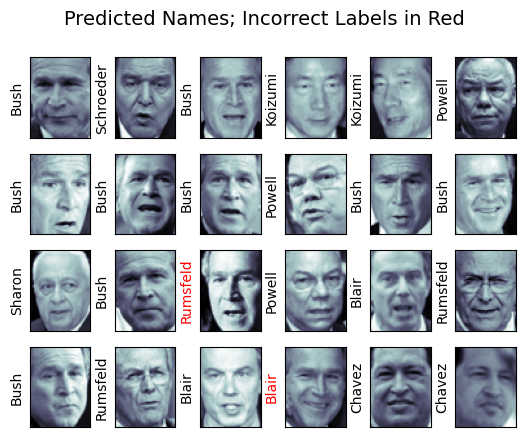

In [380]:
fig, ax = plt.subplots(4, 6)

# Menampilkan 24 gambar wajah
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')

    # Menghilangkan angka pada sumbu gambar
    axi.set(xticks=[], yticks=[])

    # Menampilkan nama belakang tokoh hasil prediksi
    # Warna merah menunjukkan prediksi yang salah
    axi.set_ylabel(
        faces.target_names[yfit[i]].split()[-1],
        color='black' if yfit[i] == ytest[i] else 'red'
    )

fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

plt.show()

### **Langkah 6 - Cek Performansi Model**

#### **6A - Classification Report**

In [381]:
from sklearn.metrics import classification_report

# Menampilkan laporan performa model
print(classification_report(
    ytest,
    yfit,
    target_names=faces.target_names
))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



#### **6B - Confusion Matrix**

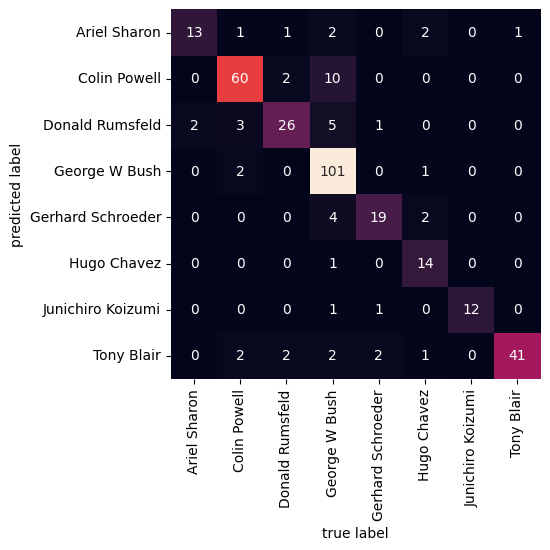

In [382]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Membuat confusion matrix
mat = confusion_matrix(ytest, yfit)

# Menampilkan confusion matrix dalam bentuk heatmap
sns.heatmap(
    mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=faces.target_names,
    yticklabels=faces.target_names
)

plt.xlabel('true label')
plt.ylabel('predicted label')

plt.show()

# **PRAKTIKUM 5**

### **Langkah 0 — Import Library dan Hubungkan Google Drive**

#### **0A - Import Library**

In [383]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

#### **0B - Hubungkan Google Drive**

In [384]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### **0C - Menentukan lokasi dataset**

In [385]:
train_dir = "/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/images/training/"
test_dir = "/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/images/test/"

### **Langkah 1 - Load Data dan Visualisasikan**

#### **1A - Membuat fungsi untuk membaca dataset**

In [386]:
# Membuat fungsi untuk membaca gambar dari folder dataset
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []

    # Membaca setiap folder label, yaitu day dan night
    for dir in dirs:
        label = dir.name

        # Membaca semua file gambar berformat JPG
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            # Menyimpan gambar dan label jika gambar berhasil dibaca
            if img is not None:
                img_list.append((img, label))

    return img_list

#### **1B - Memuat data training**

In [387]:
# Membaca seluruh gambar dari folder training
train_img = load_dataset(train_dir)

# Menampilkan jumlah gambar yang berhasil dibaca
print("Jumlah data training:", len(train_img))

Jumlah data training: 241


#### **1C - Melihat contoh data**

In [388]:
# Menampilkan salah satu data pertama
train_img[0]

(array([[[159, 221, 255],
         [118, 180, 227],
         [119, 181, 228],
         ...,
         [ 99, 162, 206],
         [ 99, 162, 206],
         [ 99, 162, 206]],
 
        [[159, 221, 255],
         [118, 180, 227],
         [119, 181, 228],
         ...,
         [ 99, 162, 206],
         [ 99, 162, 206],
         [ 99, 162, 206]],
 
        [[159, 221, 255],
         [118, 180, 227],
         [119, 181, 228],
         ...,
         [ 99, 162, 206],
         [ 99, 162, 206],
         [ 99, 162, 206]],
 
        ...,
 
        [[ 31,  36,  29],
         [ 24,  29,  22],
         [ 20,  25,  18],
         ...,
         [192, 204, 158],
         [145, 157, 117],
         [122, 137,  98]],
 
        [[ 29,  34,  27],
         [ 23,  28,  21],
         [ 20,  25,  18],
         ...,
         [185, 195, 145],
         [194, 205, 162],
         [180, 193, 150]],
 
        [[ 28,  33,  26],
         [ 23,  28,  21],
         [ 21,  26,  19],
         ...,
         [169, 177, 126],
  

#### **1D - Melihat ukuran gambar secara acak**

In [389]:
# Memilih satu gambar secara acak
pick_random = np.random.randint(0, len(train_img))

# Menampilkan nomor dan ukuran gambar
print(f'Image: {pick_random}')
print(f'Shape: {train_img[pick_random][0].shape}')

Image: 62
Shape: (700, 1280, 3)


#### **1E - Membuat fungsi visualisasi gambar acak**

In [390]:
# Membuat fungsi untuk menampilkan gambar secara acak
def random_img_viz(img_list):
    # Memilih gambar secara acak
    rand_num = np.random.randint(0, len(img_list))

    # Mengambil gambar dan label
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    # Mengubah label menjadi teks
    label_str = 'day' if label == 1 else 'night'

    # Menampilkan gambar dan informasi
    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

#### **1D — Menampilkan satu gambar training secara acak**

Shape	: (471, 640, 3)
Label	: day


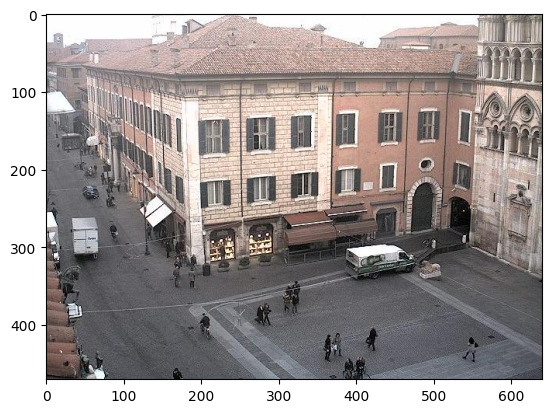

In [391]:
random_img_viz(train_img)

### **Langkah 2 - Preprocessing Data**

#### **2A - Menyamakan ukuran gambar**

In [392]:
# Fungsi standarisasi input
def standarized_input(image):
    # Mengubah ukuran gambar menjadi lebar 1100 dan tinggi 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

#### **2B  Mengubah label menjadi angka**

In [393]:
# Fungsi Encoding Label
def label_encoder(label):
    # Nilai awal label adalah 0
    num_val = 0

    # Jika label day, ubah menjadi 1
    if label == 'day':
        num_val = 1

    return num_val

#### **2C - Membuat fungsi preprocessing**

In [394]:
def preprocess(img_list):
    std_img_list = []

    # Memproses setiap gambar dalam dataset
    for item in img_list:
        image = item[0]
        label = item[1]

        # Menyamakan ukuran gambar
        std_img = standarized_input(image)

        # Mengubah label teks menjadi angka
        img_label = label_encoder(label)

        # Menyimpan gambar dan label hasil preprocessing
        std_img_list.append((std_img, img_label))

    return std_img_list

#### **2D - Melakukan preprocessing pada data training**

In [395]:
train_std_img_list = preprocess(train_img)

#### **2E - Pengecekan Ukuran Gambar Secara Acak**

In [396]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 29
(600, 1100, 3)


#### **Langkah 2F - Inspeksi Visual Gambar Hasil Preprocessing**

Shape	: (600, 1100, 3)
Label	: 1


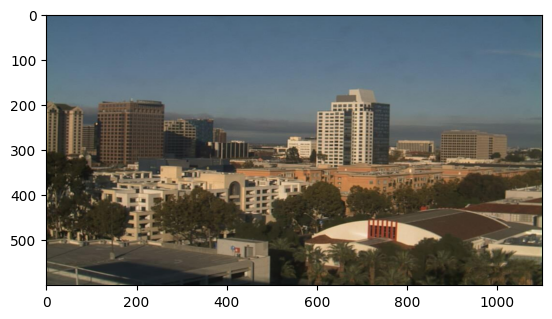

In [397]:
random_img_viz(train_std_img_list)

### **Langkah 3 - Ekstraksi Fitur Average Brightness**

#### **3A - Membuat fungsi untuk menghitung kecerahan**

In [398]:
def avg_brightness(image):
    # Mengubah gambar dari RGB menjadi HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Mengambil total nilai kecerahan dari channel V
    sum_brightness = np.sum(img_hsv[:, :, 2])

    # Menghitung luas gambar
    area = image.shape[0] * image.shape[1]

    # Menghitung rata-rata kecerahan
    avg = sum_brightness / area

    return avg

#### **3B - Menguji fungsi pada satu gambar secara acak**

Image 166
Avg Brightness: 99.3398


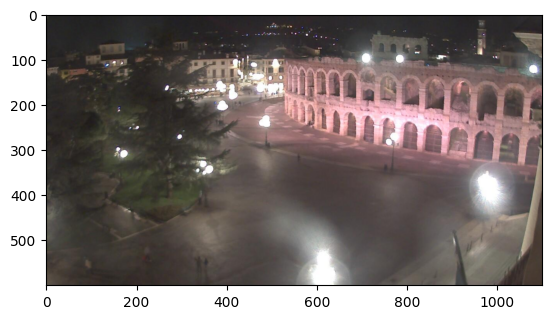

In [399]:
# Memilih gambar secara acak
rand_img = np.random.randint(0, len(train_std_img_list))

# Mengambil gambar yang dipilih
feature_img = train_std_img_list[rand_img][0]

# Menghitung rata-rata kecerahan gambar
avg_img = avg_brightness(feature_img)

# Menampilkan hasil
print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')

# Menampilkan gambar
plt.imshow(feature_img)
plt.show()

### **Langkah 4 - Klasifikasi Gambar Menggunakan Threshold**

#### **4A - Membuat fungsi prediksi label**

In [400]:
def predict_label(img, threshold):
    # Menghitung rata-rata kecerahan gambar
    avg = avg_brightness(img)

    # Label awal adalah night (0)
    pred = 0

    # Jika kecerahan melebihi threshold, prediksi day (1)
    if avg > threshold:
        pred = 1

    return pred

#### **4B - Menguji prediksi pada gambar secara acak**

Image 31
Actual label: 1
Predicted label: 1


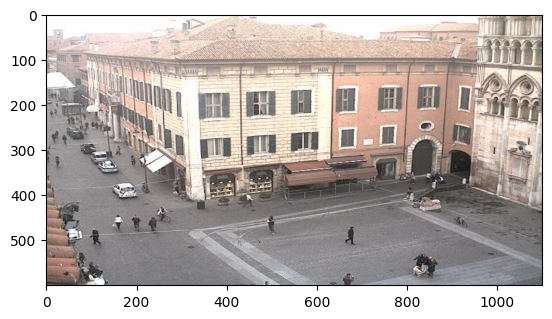

In [401]:
# Memilih gambar secara acak
rand_img = np.random.randint(0, len(train_std_img_list))

# Melakukan prediksi dengan threshold 120
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Menampilkan hasil prediksi dan label sebenarnya
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')

# Menampilkan gambar
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

### **Langkah 5 - Evaluasi Akurasi pada Data Training**

#### **5A - Membuat fungsi evaluasi**

In [402]:
# Function to Evaluate Model
def evaluate(img_list, threshold):
    # Menyimpan gambar yang salah diprediksi
    miss_labels = []

    # Memeriksa setiap gambar dalam dataset
    for file in img_list:
        img = file[0]
        label = file[1]

        # Melakukan prediksi label
        pred_label = predict_label(img, threshold)

        # Mencatat gambar jika prediksi salah
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    # Menghitung jumlah seluruh gambar
    total_img = len(img_list)

    # Menghitung jumlah prediksi yang benar
    corr_pred = total_img - len(miss_labels)

    # Menghitung akurasi
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

#### **5B - Menghitung akurasi data training**

In [403]:
# Evaluasi data training menggunakan threshold 120
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8423


### **Langkah 6 - Evaluasi Akurasi pada Data Testing**

#### **6A — Memuat dataset testing**

In [404]:
# Membaca gambar dari folder testing
test_img = load_dataset(test_dir)

# Menampilkan jumlah data testing
print("Jumlah data testing:", len(test_img))

Jumlah data testing: 160


#### **6B — Melakukan preprocessing pada data testing**

In [405]:
# Melakukan preprocessing pada dataset testing
test_std_img_list = preprocess(test_img)

# Menampilkan jumlah data setelah preprocessing
print("Jumlah data testing:", len(test_std_img_list))

# Memeriksa ukuran gambar pertama
print("Ukuran gambar:", test_std_img_list[0][0].shape)

Jumlah data testing: 160
Ukuran gambar: (600, 1100, 3)


#### **6C — Menghitung akurasi data testing**

In [406]:
# Evaluasi data testing menggunakan threshold 120
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


### **Langkah 7 - Ekstraksi Fitur untuk Klasifikasi SVM**

#### **7A — Membuat fungsi ekstraksi fitur**

In [407]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    # Mengambil nilai kecerahan dan label setiap gambar
    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    # Menggabungkan fitur dan label
    data = np.column_stack((avg_list, labels))

    # Mengubah data menjadi DataFrame
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

#### **7B — Ekstraksi fitur data training**

In [408]:
# Mengekstraksi fitur dari data training
train_avg_img = extract_avg_bright_feature(train_std_img_list)

# Menampilkan ukuran tabel
print("Ukuran data training:", train_avg_img.shape)

# Menampilkan lima baris pertama
train_avg_img.head()

Ukuran data training: (241, 2)


,AVG_BRIGHT,LABELS
0,134.983432,1.0
1,117.857553,1.0
2,132.202408,1.0
3,116.668502,1.0
4,119.708941,1.0


#### **7C — Ekstraksi fitur data testing**

In [409]:
# Mengekstraksi fitur dari data testing
test_avg_img = extract_avg_bright_feature(test_std_img_list)

# Menampilkan ukuran tabel
print("Ukuran data testing:", test_avg_img.shape)

# Menampilkan lima baris pertama
test_avg_img.head()

Ukuran data testing: (160, 2)


,AVG_BRIGHT,LABELS
0,194.228062,1.0
1,191.237441,1.0
2,157.826662,1.0
3,188.119652,1.0
4,185.917073,1.0


### **Langkah 8 - Klasifikasi Menggunakan Support Vector Machine (SVM)**

#### **8A — Import library dan menyiapkan data**

In [410]:
from sklearn.svm import SVC

# Menentukan fitur dan label data training
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]

# Menentukan fitur dan label data testing
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

#### **8B — Melatih model SVM**

In [411]:
# Membuat model SVM
model = SVC()

# Melatih model menggunakan data training
model.fit(X_train, y_train)

SVC()

### **Langkah 9 - Evaluasi Model SVM**

In [412]:
from sklearn.metrics import accuracy_score

# Melakukan prediksi pada data training
y_train_pred = model.predict(X_train)

# Menghitung akurasi data training
acc_train = accuracy_score(y_train, y_train_pred)

# Melakukan prediksi pada data testing
y_test_pred = model.predict(X_test)

# Menghitung akurasi data testing
acc_test = accuracy_score(y_test, y_test_pred)

# Menampilkan hasil evaluasi
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8589211618257261
Accuracy on test: 0.9


# **TUGAS PRAKTIKUM**

## **Bagian 1 — Klasifikasi Dataset voice.csv**

### **Langkah 1 - Memuat Dataset voice.csv**

In [413]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')


df = pd.read_csv(
    '/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/voice.csv')

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


### **Langkah 2 - Memeriksa Informasi Dataset**

In [414]:
# Menampilkan jumlah baris dan kolom
print("Ukuran dataset:", df.shape)

Ukuran dataset: (3168, 21)


In [415]:
# Menampilkan informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

In [416]:
# Memeriksa jumlah data kosong
print("Jumlah data kosong:", df.isnull().sum().sum())

Jumlah data kosong: 0


In [417]:
# Menampilkan jumlah data pada setiap label
print(df['label'].value_counts())

label
male      1584
female    1584
Name: count, dtype: int64


### **Langkah 3 - Membagi Dataset Menjadi Data Training dan Testing**

In [418]:
from sklearn.model_selection import train_test_split

# Mengambil fitur dan label dari dataset
X = df.drop('label', axis=1)
y = df['label']


# Membagi dataset dengan rasio 70:30
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Membagi dataset dengan rasio 80:20
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data pada setiap pembagian
print("Pembagian 70:30")
print("Data training:", len(X_train_70))
print("Data testing:", len(X_test_70))

print("\nPembagian 80:20")
print("Data training:", len(X_train_80))
print("Data testing:", len(X_test_80))

Pembagian 70:30
Data training: 2217
Data testing: 951

Pembagian 80:20
Data training: 2534
Data testing: 634


### **Langkah 4 - Melatih dan Menguji Model SVM**

In [419]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Menentukan jenis kernel yang akan diuji
kernels = ['linear', 'poly', 'rbf']

# Menyimpan hasil akurasi setiap model
hasil = []

# Menyiapkan dua skenario pembagian dataset
pembagian = [
    ('70:30', X_train_70, X_test_70, y_train_70, y_test_70),
    ('80:20', X_train_80, X_test_80, y_train_80, y_test_80)
]

# Melatih dan menguji setiap model
for rasio, X_train, X_test, y_train, y_test in pembagian:
    for kernel in kernels:

        # Membuat pipeline normalisasi dan model SVM
        model = Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel=kernel))
        ])

        # Melatih model menggunakan data training
        model.fit(X_train, y_train)

        # Melakukan prediksi pada data testing
        prediksi = model.predict(X_test)

        # Menghitung akurasi model
        akurasi = accuracy_score(y_test, prediksi) * 100

        # Menyimpan hasil pengujian
        hasil.append({
            'Rasio Data': rasio,
            'Kernel': kernel,
            'Akurasi (%)': round(akurasi, 2)
        })

# Menampilkan hasil akurasi dalam bentuk tabel
df_hasil = pd.DataFrame(hasil)
display(df_hasil)

,Rasio Data,Kernel,Akurasi (%)
0,70:30,linear,97.90
1,70:30,poly,96.00
2,70:30,rbf,98.32
3,80:20,linear,97.48
4,80:20,poly,95.58
5,80:20,rbf,98.26


### **Langkah 5 - Membandingkan Hasil Akurasi Model SVM**

In [420]:
# Mengurutkan hasil berdasarkan akurasi tertinggi
df_perbandingan = df_hasil.sort_values(
    by='Akurasi (%)',
    ascending=False
).reset_index(drop=True)

# Menampilkan hasil perbandingan
print("Perbandingan Akurasi Model SVM:")
display(df_perbandingan)
print("\n")

# Menampilkan model dengan akurasi tertinggi
model_terbaik = df_perbandingan.iloc[0]

print("Model dengan akurasi tertinggi:")
print("Rasio data:", model_terbaik['Rasio Data'])
print("Kernel:", model_terbaik['Kernel'])
print("Akurasi:", model_terbaik['Akurasi (%)'], "%")

Perbandingan Akurasi Model SVM:


,Rasio Data,Kernel,Akurasi (%)
0,70:30,rbf,98.32
1,80:20,rbf,98.26
2,70:30,linear,97.90
3,80:20,linear,97.48
4,70:30,poly,96.00
5,80:20,poly,95.58




Model dengan akurasi tertinggi:
Rasio data: 70:30
Kernel: rbf
Akurasi: 98.32 %


### **Langkah 6 - Membuat Grafik Perbandingan Akurasi**

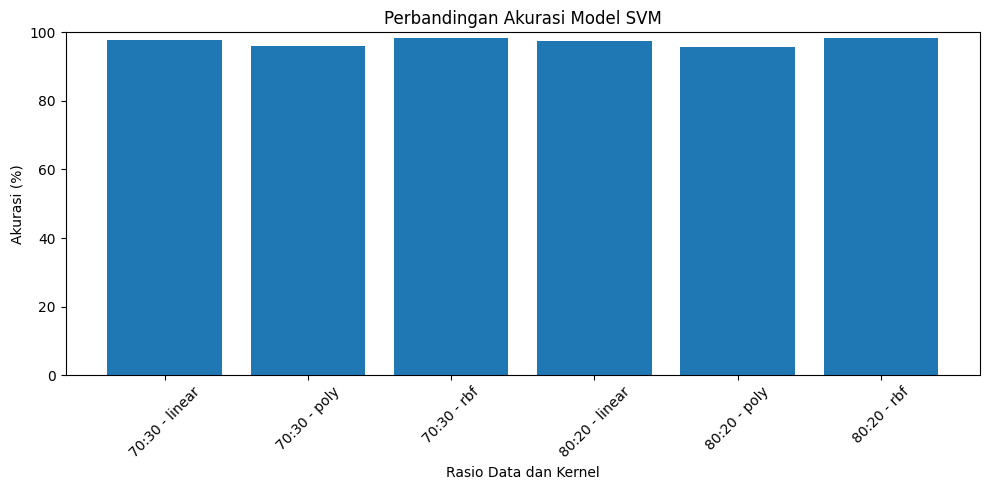

In [421]:
import matplotlib.pyplot as plt

# Membuat label untuk setiap model
label_model = (
    df_hasil['Rasio Data'] + ' - ' + df_hasil['Kernel']
)


plt.figure(figsize=(10, 5))
plt.bar(label_model, df_hasil['Akurasi (%)'])


plt.title('Perbandingan Akurasi Model SVM')
plt.xlabel('Rasio Data dan Kernel')
plt.ylabel('Akurasi (%)')

plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()


plt.show()

## **Bagian 2 - Klasifikasi Citra Siang dan Malam Menggunakan SVM Kernel RBF dengan Fitur Histogram**

### **Langkah 1 - Load Dataset**

#### **1A - Import Library dan Menghubungkan Google Drive**

In [422]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### **1B - Menentukan Lokasi Dataset**

In [423]:
train_dir = "/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/images/training/"
test_dir = "/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/images/test/"

#### **1C - Membuat Fungsi untuk Memuat Dataset**

In [424]:
# Membuat fungsi untuk membaca gambar dari folder dataset
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []

    # Membaca setiap folder label, yaitu day dan night
    for dir in dirs:
        label = dir.name

        # Membaca semua file gambar berformat JPG
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            # Menyimpan gambar dan label jika gambar berhasil dibaca
            if img is not None:
                img_list.append((img, label))

    return img_list

#### **1D - Memuat Dataset dan Menampilkan Jumlah Data**

In [425]:
train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print("Jumlah data training :", len(train_img))
print("Jumlah data testing  :", len(test_img))

Jumlah data training : 241
Jumlah data testing  : 160


### **Langkah 2 - Preprocessing Data**

#### **2A - Membuat Fungsi Standarisasi Gambar**

In [426]:
# Fungsi standarisasi input
def standarized_input(image):
    # Mengubah ukuran gambar menjadi lebar 1100 dan tinggi 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

#### **2B - Membuat Fungsi Label Encoder**

In [427]:
# Fungsi Encoding Label
def label_encoder(label):
    # Nilai awal label adalah 0
    num_val = 0

    # Jika label day, ubah menjadi 1
    if label == 'day':
        num_val = 1

    return num_val

#### **2C - Membuat fungsi preprocessing**

In [428]:
def preprocess(img_list):
    std_img_list = []

    # Memproses setiap gambar dalam dataset
    for item in img_list:
        image = item[0]
        label = item[1]

        # Menyamakan ukuran gambar
        std_img = standarized_input(image)

        # Mengubah label teks menjadi angka
        img_label = label_encoder(label)

        # Menyimpan gambar dan label hasil preprocessing
        std_img_list.append((std_img, img_label))

    return std_img_list

#### **2D - Melakukan Preprocessing pada Dataset**

In [429]:
# Melakukan preprocesing pada data Training
train_std_img_list = preprocess(train_img)

# Melakukan preprocessing pada data testing
test_std_img_list = preprocess(test_img)

#### **2E - Pengecekan Ukuran Gambar Secara Acak**

In [430]:
pick_random_training = np.random.randint(0, len(train_std_img_list))

pick_random_testing = np.random.randint(0, len(test_std_img_list))

print("Data Training")
print(f'Image {pick_random_training }')
print(train_std_img_list[pick_random_training ][0].shape)
print("\n")
print("Data Testing")
print(f'Image {pick_random_testing}')
print(test_std_img_list[pick_random_testing][0].shape)

Data Training
Image 33
(600, 1100, 3)


Data Testing
Image 90
(600, 1100, 3)


### **Langkah 3 - Menggabungkan Dataset**

In [431]:
# Menggabungkan data training dan testing
all_std_img_list = train_std_img_list + test_std_img_list

print("Jumlah seluruh data:", len(all_std_img_list))

Jumlah seluruh data: 401


### **Langkah 4 - Ekstraksi Fitur Histogram**

#### **4A - Membuat Fungsi Ekstraksi Histogram**

In [432]:
def extract_histogram(img_list):
    features = []
    labels = []

    for image, label in img_list:
        # Menghitung histogram kanal RGB, masing-masing 32 bin
        hist_r = cv2.calcHist([image], [0], None, [32], [0, 256])
        hist_g = cv2.calcHist([image], [1], None, [32], [0, 256])
        hist_b = cv2.calcHist([image], [2], None, [32], [0, 256])

        # Menggabungkan dan menormalisasi histogram
        hist = np.concatenate([hist_r, hist_g, hist_b])
        hist = cv2.normalize(hist, hist).flatten()

        features.append(hist)
        labels.append(label)

    return np.array(features), np.array(labels)

#### **4B - Mengekstraksi Fitur Seluruh Dataset**

In [433]:
# Mengekstraksi fitur dan label seluruh gambar
X, y = extract_histogram(all_std_img_list)

print("Ukuran fitur :", X.shape)
print("Ukuran label :", y.shape)

Ukuran fitur : (401, 96)
Ukuran label : (401,)


### **Langkah 5 - Membagi Data Training dan Testing**

In [434]:
from sklearn.model_selection import train_test_split

# Membagi data dengan rasio 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data hasil pembagian
print("Jumlah data training :", len(X_train))
print("Jumlah data testing  :", len(X_test))

Jumlah data training : 320
Jumlah data testing  : 81


### **Langkah 6 - Membuat Model SVM dengan Kernel RBF**

In [445]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Membuat model SVM dengan kernel RBF
model = SVC(kernel='rbf', C=1.0, gamma='scale')

# Melatih model menggunakan data training
model.fit(X_train, y_train)

# Melakukan prediksi pada data training
y_train_pred = model.predict(X_train)

# Menghitung akurasi data training
acc_train = accuracy_score(y_train, y_train_pred)*100

# Melakukan prediksi pada data testing
y_test_pred = model.predict(X_test)

# Menghitung akurasi data testing
acc_test = accuracy_score(y_test, y_test_pred)*100

# Menampilkan hasil evaluasi
print("Accuracy train: ",round(acc_train, 2), "%")
print("Accuracy test: ",round(acc_test, 2), "%")

Accuracy train:  99.69 %
Accuracy test:  100.0 %


### **Langkah 7 - Tuning Hyperparameter SVM**

#### **7A - Melakukan Tuning Hyperparameter**

In [436]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Menentukan parameter yang akan diuji
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}

# Membuat model SVM dengan kernel RBF
model = SVC(kernel='rbf')

# Mencari parameter terbaik
grid_search = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=SVC(), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10, 100],
                         'gamma': ['scale', 0.01, 0.1, 1]},
             scoring='accuracy')

#### **7B - Membuat Tabel Perbandingan Hasil Tuning**

In [437]:
# Mengambil hasil tuning ke dalam DataFrame
df_hasil = pd.DataFrame(grid_search.cv_results_)

# Membuat tabel perbandingan parameter dan akurasi
df_perbandingan = pd.DataFrame({
    'C': df_hasil['param_C'],
    'Gamma': df_hasil['param_gamma'],
    'Akurasi Validasi (%)': df_hasil['mean_test_score'] * 100
})

# Mengurutkan hasil berdasarkan akurasi tertinggi
df_perbandingan = df_perbandingan.sort_values(
    by='Akurasi Validasi (%)',
    ascending=False
).reset_index(drop=True)

# Menampilkan hasil perbandingan
print("Perbandingan Hasil Tuning SVM RBF:")
display(df_perbandingan)
print("\n")

# Menampilkan parameter dengan akurasi validasi tertinggi
parameter_terbaik = df_perbandingan.iloc[0]

print("Parameter dengan akurasi validasi tertinggi:")
print("C:", parameter_terbaik['C'])
print("Gamma:", parameter_terbaik['Gamma'])
print("Akurasi Validasi:",round(parameter_terbaik['Akurasi Validasi (%)'], 2), "%")

Perbandingan Hasil Tuning SVM RBF:


,C,Gamma,Akurasi Validasi (%)
0,1.0,scale,99.0625
1,100.0,0.1,99.0625
2,10.0,1,99.0625
3,100.0,1,99.0625
4,100.0,scale,99.0625
5,10.0,scale,99.0625
6,1.0,1,98.7500
7,10.0,0.1,98.4375
8,100.0,0.01,98.4375
9,1.0,0.1,93.4375




Parameter dengan akurasi validasi tertinggi:
C: 1.0
Gamma: scale
Akurasi Validasi: 99.06 %


### **Langkah 8 - Evaluasi Model Terbaik**

In [438]:
# Mengambil model dengan parameter terbaik
best_model = grid_search.best_estimator_

# Memprediksi data testing
y_pred_best = best_model.predict(X_test)

# Menghitung akurasi testing
akurasi_best = accuracy_score(y_test, y_pred_best) * 100

print("Parameter terbaik:", grid_search.best_params_)
print("Akurasi testing terbaik:", round(akurasi_best, 2), "%")

Parameter terbaik: {'C': 1, 'gamma': 'scale'}
Akurasi testing terbaik: 100.0 %


### **Langkah 9 - Evaluasi Menggunakan Confusion Matrix dan Classification Report**

#### **9A - Confusion Matrix**

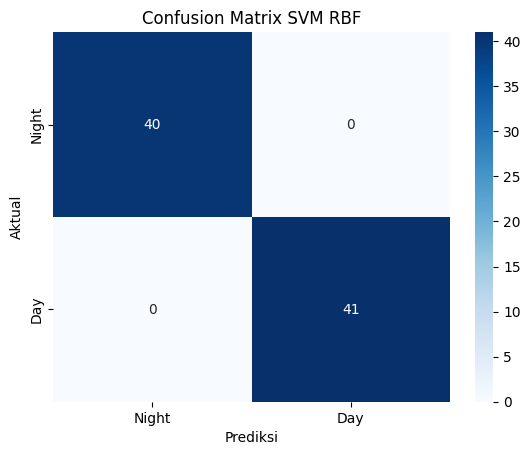

In [439]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Night', 'Day'],
            yticklabels=['Night', 'Day'])

plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix SVM RBF')
plt.show()

#### **9B - Classification Report**

In [440]:
from sklearn.metrics import classification_report

hasil_report = classification_report(
    y_test, y_pred_best,
    labels=[0, 1],
    target_names=['Night', 'Day'],
    zero_division=0
)

print(hasil_report)

              precision    recall  f1-score   support

       Night       1.00      1.00      1.00        40
         Day       1.00      1.00      1.00        41

    accuracy                           1.00        81
   macro avg       1.00      1.00      1.00        81
weighted avg       1.00      1.00      1.00        81



### **Langkah 10 - Kesimpulan Hasil Klasifikasi**

In [441]:
# Menampilkan ringkasan hasil model terbaik
print("Kernel             : RBF")
print("Parameter terbaik :", grid_search.best_params_)
print("Akurasi validasi   :", round(grid_search.best_score_ * 100, 2), "%")
print("Akurasi testing    :", round(akurasi_best, 2), "%")

Kernel             : RBF
Parameter terbaik : {'C': 1, 'gamma': 'scale'}
Akurasi validasi   : 99.06 %
Akurasi testing    : 100.0 %
